# 第8章　能動学習の基礎

第6章と同じ材料で、今度は次の試験片が74 MPa以上になる確率を温度範囲全体で学びます。安価な候補一覧（温度）と高価なラベル（合否）を区別します。最初は候補1点を選び、その後でランダム選択・予測エントロピー・BALDを同じラベル予算で比較します。

In [1]:
import json
from time import perf_counter

import matplotlib.pyplot as plt
import torch
from robotorchan.acquisition import BALD, PredictiveEntropy, qPosteriorVariance

from classification_experiment import (
    FIT_EPOCHS, bernoulli_entropy, fit_classifier, pass_probability, reveal_labels, uniforms,
)
from experiment import BLUE, DTYPE, INK, ORANGE, QUALITY, SEED, fit_material_gp, observations, save_figure, setup

setup()
torch.set_default_dtype(DTYPE)
pool = torch.linspace(0, 1, 81, dtype=DTYPE).unsqueeze(-1)
initial = torch.tensor([0, 20, 52, 76])
available = torch.ones(len(pool), dtype=torch.bool)
available[initial] = False
remaining = torch.where(available)[0]
draws = uniforms(pool, SEED)
initial_y = reveal_labels(pool[initial], draws[initial])

model = fit_classifier(pool[initial], initial_y, seed=SEED)
with torch.no_grad():
    candidate_batches = pool[remaining].unsqueeze(-2)
    entropy = PredictiveEntropy(model)(candidate_batches)
    bald = BALD(model)(candidate_batches)
    next_index = remaining[bald.argmax()]
new_label = reveal_labels(pool[next_index], draws[next_index]).item()
print("初期ラベル:", initial_y[:, 0].int().tolist())
print(f"BALDが選んだ温度: {140 + 40 * pool[next_index].item():.1f} °C、合否: {new_label:.0f}")

初期ラベル: [1, 1, 0, 1]
BALDが選んだ温度: 160.5 °C、合否: 1


`pool` は $(81,1)$、1点ずつ評価する獲得関数の入力は $(77,1,1)$ です。先頭軸は選択肢、中央軸は1回に調べる候補数 $q=1$、末尾軸は特徴量数です。`argmax` で得るのは絞り込んだ配列の添字です。`remaining` で元の候補番号へ戻してからラベルを問い合わせます。同点は最初の候補を採用します。

## 8.2 同じ予測確率でも、ラベルの役立ち方は異なる

確率 $P$ の分布をAとBで変えます。Aは常に $P=0.5$、Bは $P=0.1,0.9$ が等確率です。予測ラベルの分布はどちらもBernoulli(0.5)です。この簡単な例のBALDは $h(\mathbb E[P])-\mathbb E[h(P)]$ を直接計算できます。

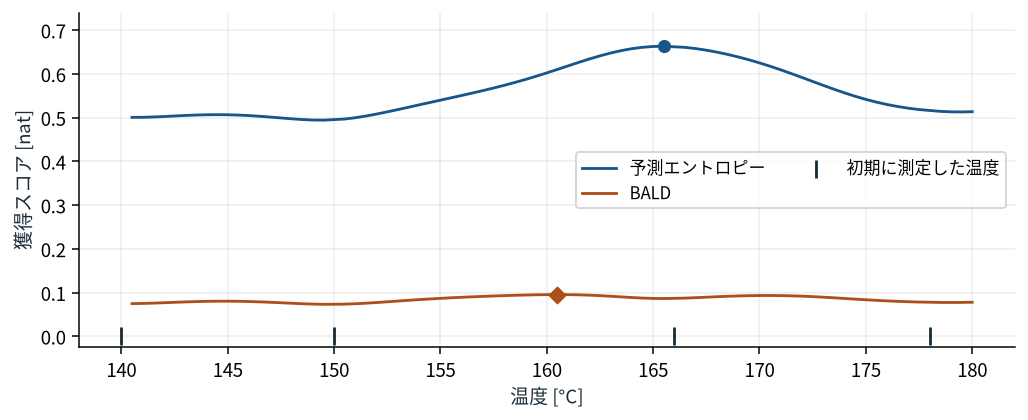

In [2]:
example_p = torch.tensor([[0.5, 0.5], [0.1, 0.9]])
example_h = bernoulli_entropy(example_p.mean(dim=1))
example_conditional = bernoulli_entropy(example_p).mean(dim=1)
example_information = example_h - example_conditional
assert torch.allclose(example_h, torch.full_like(example_h, torch.log(torch.tensor(2.0))))
with torch.no_grad():
    conditional = model.expected_class_entropy(candidate_batches).flatten()
torch.testing.assert_close(bald, (entropy - conditional).clamp_min(0), atol=1e-10, rtol=1e-10)

temperature = 140 + 40 * pool[:, 0]
fig, ax = plt.subplots(figsize=(7.5, 3.0), layout="constrained")
ax.plot(temperature[remaining], entropy, color=BLUE, label="予測エントロピー")
ax.plot(temperature[remaining], bald, color=ORANGE, label="BALD")
ax.scatter(temperature[remaining[entropy.argmax()]],
           entropy.max(), color=BLUE, marker="o", zorder=4)
ax.scatter(temperature[next_index], bald.max(), color=ORANGE, marker="D", zorder=4)
ax.scatter(temperature[initial], torch.zeros(len(initial)), marker="|", s=95,
           color=INK, label="初期に測定した温度")
ax.set(xlabel="温度 [°C]", ylabel="獲得スコア [nat]", ylim=(-0.025, 0.74))
ax.legend(fontsize=9, ncol=2, loc="center right")
save_figure(fig, "ch08_entropy_bald")

## 8.3 回帰の能動学習

第4章の実数値の測定を使います。分散最大の温度と事後平均最大の温度を同じ候補集合で比べます。分散は潜在強度のもので、単位は MPa² です。使ったGPの測定ノイズの分散は温度によらず一定です。

In [3]:
reg_x, reg_y, reg_var = observations()
reg_model = fit_material_gp(reg_x, reg_y, reg_var)
already_measured = torch.isclose(pool, reg_x.T).any(dim=1)
reg_pool = pool[~already_measured].unsqueeze(-2)
with torch.no_grad():
    latent_variance = qPosteriorVariance(reg_model)(reg_pool)
    latent_mean = reg_model.posterior(reg_pool).mean.reshape(-1)
variance_temperature = 140 + 40 * reg_pool[latent_variance.argmax()].item()
mean_temperature = 140 + 40 * reg_pool[latent_mean.argmax()].item()
print(f"分散最大: {variance_temperature:.1f} °C、平均最大: {mean_temperature:.1f} °C")

分散最大: 140.0 °C、平均最大: 152.0 °C


## 8.4 等しいラベル予算で比較する

20通りのシードで、初期4件とそこから追加する6件の実験を行います。各シード内で初期ラベルと候補ごとの乱数を共有し、モデルは毎回同じ設定で学習し直します。ランダム方策は残った候補から一様に1点ずつ選びます。

評価には温度グリッドの間に置いた80点を使います。各温度の真の合格確率 $r$ が分かるシミュレーションなので、誤差の計算にラベルをもう一度引く必要はありません。Brier損失の条件付き期待値 $r(1-p)^2+(1-r)p^2$ を温度全体で平均します。候補選択やモデル学習の入力には使いません。

In [4]:
test_x = (torch.arange(80, dtype=DTYPE) + 0.5).unsqueeze(-1) / 80
assert not torch.isclose(test_x, pool.T).any()
truth = pass_probability(test_x).flatten()
seeds = list(range(SEED, SEED + 20))
additional = 6
strategies = {"random": None, "entropy": PredictiveEntropy, "bald": BALD}


def learning_run(seed, strategy):
    draws = uniforms(pool, seed)
    random_policy = torch.Generator().manual_seed(seed + 1000)
    chosen = initial.tolist()
    labels = reveal_labels(pool[initial], draws[initial])
    available = torch.ones(len(pool), dtype=torch.bool)
    available[initial] = False
    losses = []
    for step in range(additional + 1):
        model = fit_classifier(pool[chosen], labels, seed=seed + step)
        with torch.no_grad():
            p = model.predict_proba(test_x)[..., 1]
            loss = (truth * (1 - p).square() + (1 - truth) * p.square()).mean()
            losses.append(loss.item())
            if step == additional:
                break
            remaining = torch.where(available)[0]
            if strategy is None:
                position = torch.randint(len(remaining), (1,), generator=random_policy).item()
            else:
                position = strategy(model)(pool[remaining].unsqueeze(-2)).argmax().item()
        index = remaining[position].item()
        chosen.append(index)
        available[index] = False
        labels = torch.cat((labels, reveal_labels(pool[index:index + 1], draws[index:index + 1])))
    assert len(chosen) == len(set(chosen)) == len(initial) + additional
    return {"seed": seed, "indices": chosen, "labels": labels[:, 0].int().tolist(), "brier": losses}


started = perf_counter()
trials = {name: [learning_run(seed, strategy) for seed in seeds]
          for name, strategy in strategies.items()}
elapsed = perf_counter() - started
for baseline, entropy_run, bald_run in zip(*trials.values()):
    assert baseline["labels"][:4] == entropy_run["labels"][:4] == bald_run["labels"][:4]
    assert baseline["brier"][0] == entropy_run["brier"][0] == bald_run["brier"][0]
curves = {name: torch.tensor([row["brier"] for row in runs]) for name, runs in trials.items()}
for name, values in curves.items():
    print(f"{name:>7s}: 初期 {values[:, 0].quantile(0.5):.4f}、10件 {values[:, -1].quantile(0.5):.4f}")

 random: 初期 0.2398、10件 0.1517
entropy: 初期 0.2398、10件 0.1461
   bald: 初期 0.2398、10件 0.1510


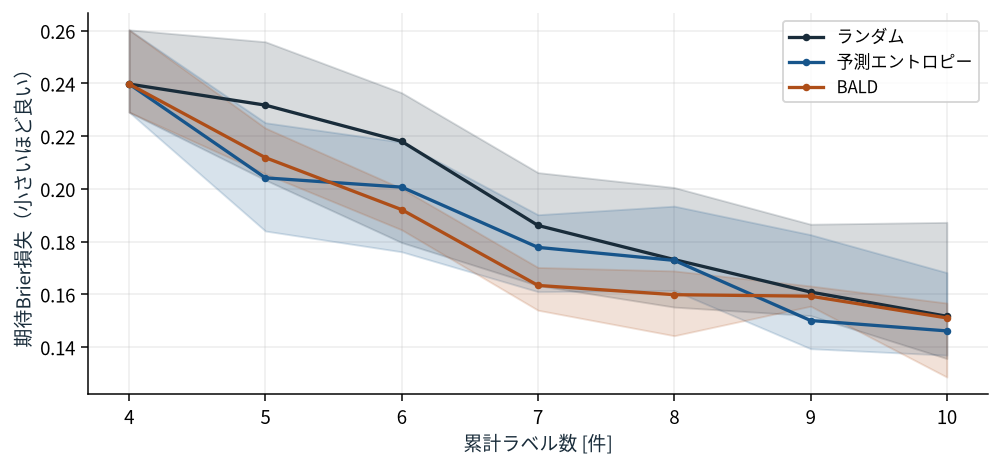

In [5]:
fig, ax = plt.subplots(figsize=(7.3, 3.35), layout="constrained")
counts = torch.arange(len(initial), len(initial) + additional + 1)
for (name, values), color, label in zip(
    curves.items(), (INK, BLUE, ORANGE), ("ランダム", "予測エントロピー", "BALD")
):
    q1, med, q3 = torch.quantile(values, values.new_tensor([0.25, 0.5, 0.75]), dim=0)
    ax.fill_between(counts, q1, q3, color=color, alpha=0.17)
    ax.plot(counts, med, marker="o", markersize=3, color=color, label=label, linewidth=1.75)
ax.set(xlabel="累計ラベル数 [件]", ylabel="期待Brier損失（小さいほど良い）", xticks=counts)
ax.legend(fontsize=9)
save_figure(fig, "ch08_learning_curves")

metrics = {
    "pool_size": len(pool), "test_size": len(test_x), "fit_epochs": FIT_EPOCHS,
    "initial_temperatures_c": temperature[initial].tolist(), "initial_labels": initial_y[:, 0].int().tolist(),
    "first_entropy_temperature_c": temperature[remaining[entropy.argmax()]].item(),
    "first_bald_temperature_c": temperature[next_index].item(), "first_bald_label": int(new_label),
    "worked_bald": example_information.tolist(), "entropy_decomposition_error": (bald - entropy + conditional).abs().max().item(),
    "regression_variance_temperature_c": variance_temperature, "regression_mean_temperature_c": mean_temperature,
    "counts": counts.tolist(), "trials": trials, "benchmark_seconds": elapsed,
}
(QUALITY / "ch08_metrics.json").write_text(json.dumps(metrics, indent=2) + chr(10), encoding="utf-8")

実線は各ラベル数の中央値、帯は第1〜第3四分位です。途中で損失が上がる場合は、追加されたラベルとモデルの変化を照合してください。発展課題では、運用温度の分布を変えたときの評価を比べます。